# Evidence: every design choice in C4 was chosen by comparing it with alternatives

**Why this notebook exists.** A design choice is only convincing if the alternatives were tried and the numbers are visible. This notebook shows, choice by choice, **what was compared, the numbers, and which option won**. Where possible the comparison is **run again live** (so you can show it is not typed in by hand); where it needs a GPU or the slow LLM server, the numbers are read from the saved result files in `data/results/`.

| # | Choice | Alternatives compared | Evidence type |
|---|---|---|---|
| 1 | Stage-1 embedding model | MiniLM, code-search model, UniXcoder, TF-IDF, hybrid (7 datasets) | **re-run live** |
| 2 | Stage-1 with a fine-tuned CodeBERT | TF-IDF + MiniLM vs adding CodeBERT (7 real projects) | saved result |
| 3 | Cross-encoder reranker | stage 1 alone vs reranker (CodeBERT / MiniLM) | saved result |
| 4 | Query expansion with the LLM | with vs without | saved result |
| 5 | The verifier LLM | Llama 3.1 8B vs Qwen2.5-coder vs Gemma 2 | saved result |
| 6 | The verification prompt | expert vs evidence prompt | saved result |
| 7 | Decay detection | LLM only vs LLM + meaning-change check | saved result |

**Read each section as:** question → what was compared → numbers → decision → limits.

## 1. Environment

Finds the project folder. No GPU, Neo4j or LLM is needed for this notebook; section 3 runs the embedding models that are already on this computer.

In [1]:
import os, sys, json, time
from pathlib import Path
os.environ.setdefault('HF_HUB_OFFLINE', '1')        # the models are already on this computer: nothing is downloaded
ROOT = Path.cwd().resolve()
while not (ROOT / 'agents').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
RESULTS = ROOT / 'data' / 'results'
def saved(name): return json.loads((RESULTS / name).read_text(encoding='utf-8'))
print('project folder:', ROOT); print('result files found:', len(list(RESULTS.glob('*.json'))))

project folder: /Users/habbglobal/Desktop/J26-SE-327/project
result files found: 23


## Plot style

One small cell that makes every graph below look the same (clean grid, no top/right border) and gives each method its own colour, so a method has the same colour in every graph.

In [2]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
COLORS = {'TF-IDF': '#9aa5b1', 'MiniLM': '#4c78a8', 'CodeBERT (not trained)': '#c9a227', 'CodeBERT (fine-tuned)': '#d1495b',
          'TF-IDF + MiniLM': '#2f6f4e', 'TF-IDF + CodeBERT (fine-tuned)': '#9b5de5', 'TF-IDF + MiniLM + CodeBERT': '#e07a1f'}
def color(name):
    return COLORS.get(name, '#444444')

def show_table(rows, columns, width=44):
    """Print {name: {metric: value}} as an aligned text table."""
    print(f"{'':{width}s}" + ''.join(f'{c:>10s}' for c in columns))
    for name, r in rows.items():
        print(f'{name:{width}s}' + ''.join(f'{r[c]:10.3f}' for c in columns))

## 2. How a comparison is made fair

Every comparison below follows the same rules, so a difference is caused by the choice and not by the setup:

* **Same data** for every option (the same requirements, the same code files, the same expert answer key).
* **Same metric:** *recall@k* = of all true links, the share found in each requirement's top k files. A model that puts the true links higher scores higher.
* **Same pipeline code** (`retrieval.py`), so the only thing that changes is the model being compared.
* **Seven public datasets with expert-labelled links** (iTrust, eTour, SMOS, eANCI, LibEST, CM-1, EBT), not one cherry-picked project.

## 3. Choice 1: which embedding model for stage 1? (re-run live)

**Question.** Stage 1 needs a model that turns requirements and code into vectors. Is a general model (MiniLM) enough, or does a code-specific model do better?

**Compared**
* **MiniLM** (`all-MiniLM-L6-v2`): general-purpose sentence model.
* **code-search** (`st-codesearch-distilroberta-base`): trained to match natural-language queries to code.
* **UniXcoder** (`unixcoder-base`): trained on code and comments.
* **TF-IDF**: word counting, no model.
* **hybrid** = TF-IDF + the embedding, fused by z-score (what the pipeline uses).

No model is trained here: each is used as it was published. The cell below **runs all of them now**, on all seven datasets, with the pipeline's own functions (a few minutes).

In [3]:
from agents.traceability_agent.preprocess import retrieval_text
from agents.traceability_agent.retrieval import embedding_matrix, tfidf_matrix, zscore_fuse
from agents.traceability_agent.config import CHUNK_WORDS
from shared.embeddings.embedder import Embedder
from shared.schemas.traceability import Artifact

DATASETS = ['itrust', 'etour', 'smos', 'eanci', 'libest', 'cm1', 'ebt']
MODELS = {'MiniLM': 'all-MiniLM-L6-v2', 'code-search': 'flax-sentence-embeddings/st-codesearch-distilroberta-base', 'UniXcoder': 'microsoft/unixcoder-base'}
KS = (5, 10, 20)

def load(name):
    P = ROOT / 'data' / 'processed' / name
    arts = [Artifact(**a) for a in json.loads((P / 'artifacts.json').read_text(encoding='utf-8'))]
    traces = json.loads((P / 'traces.json').read_text(encoding='utf-8'))
    reqs, code_ = [a for a in arts if a.type == 'requirement'], [a for a in arts if a.type != 'requirement']
    ri, ci = {a.id: i for i, a in enumerate(reqs)}, {a.id: i for i, a in enumerate(code_)}
    gold = {}
    for t in traces:
        if t['source_id'] in ri and t['target_id'] in ci: gold.setdefault(ri[t['source_id']], set()).add(ci[t['target_id']])
    return reqs, code_, gold

def recall(matrix, gold, k):
    hit = total = 0
    for i, truth in gold.items():
        hit += len(truth & set(np.argsort(-matrix[i])[:k].tolist())); total += len(truth)
    return hit / total

embedders = {name: Embedder(path) for name, path in MODELS.items()}
live = {}
t0 = time.time()
for ds in DATASETS:
    reqs, code_, gold = load(ds)
    tf = tfidf_matrix(reqs, code_, retrieval_text, CHUNK_WORDS)
    live[ds] = {'TF-IDF': {k: recall(tf, gold, k) for k in KS}}
    for name, emb in embedders.items():
        m = embedding_matrix(reqs, code_, emb, retrieval_text, CHUNK_WORDS)
        live[ds][name + ' (embedding)'] = {k: recall(m, gold, k) for k in KS}
        live[ds][name + ' + TF-IDF'] = {k: recall(zscore_fuse([tf, m]), gold, k) for k in KS}
    print(f'{ds:7s} done ({time.time() - t0:.0f} s)')

/Users/habbglobal/Desktop/J26-SE-327/project/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/habbglobal/Desktop/J26-SE-327/project/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
No sentence-transformers model found with name microsoft/unixcoder-base. Creating a new one with mean pooling.


itrust  done (45 s)
etour   done (65 s)
smos    done (77 s)
eanci   done (87 s)
libest  done (107 s)
cm1     done (109 s)
ebt     done (112 s)


### Does the live run match the numbers saved earlier?

A comparison is only evidence if it can be reproduced. The cell compares each live number with the saved one (`stage1_embeddings.json`) and reports the largest difference.

In [4]:
ref = saved('stage1_embeddings.json')
worst = 0.0; checked = 0
for ds in ref:                                              # the saved file has the six datasets it was made for
    for name in MODELS:
        for k in KS:
            a, b = live[ds][name + ' + TF-IDF'][k], ref[ds][name]['hybrid'][str(k)]
            worst = max(worst, abs(a - b)); checked += 1
print(f'{checked} numbers compared; largest difference between live and saved: {worst:.3f}')
print('REPRODUCED: the live run gives the same numbers as the saved results.' if worst < 0.01 else 'NOT identical: the data, the pipeline or the models changed since the saved run.')

63 numbers compared; largest difference between live and saved: 0.000
REPRODUCED: the live run gives the same numbers as the saved results.


### Result: recall@10 of the full pipeline (hybrid) on each dataset

Higher is better. The bars show, for each dataset, how many of the true links are found in the top 10 files of their requirement.

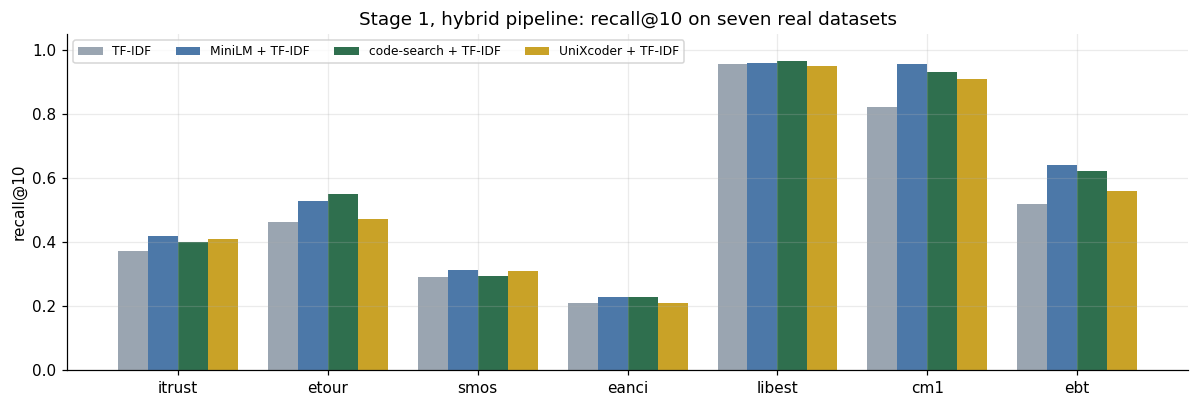

In [5]:
names = ['TF-IDF', 'MiniLM + TF-IDF', 'code-search + TF-IDF', 'UniXcoder + TF-IDF']
x = np.arange(len(DATASETS)); w = 0.2
fig, ax = plt.subplots(figsize=(11, 3.8))
for j, n in enumerate(names):
    ax.bar(x + (j - 1.5) * w, [live[d][n][10] for d in DATASETS], w, label=n, color=['#9aa5b1', '#4c78a8', '#2f6f4e', '#c9a227'][j])
ax.set_xticks(x); ax.set_xticklabels(DATASETS); ax.set_ylabel('recall@10'); ax.set_ylim(0, 1.05); ax.legend(fontsize=8, ncol=4)
ax.set_title('Stage 1, hybrid pipeline: recall@10 on seven real datasets'); plt.tight_layout(); plt.show()

### Result table and the decision

The table gives the **average over the seven datasets** (each dataset counts once), for the embedding alone and for the hybrid.

In [6]:
avg = {n: {k: float(np.mean([live[d][n][k] for d in DATASETS])) for k in KS} for n in live[DATASETS[0]]}
print(f"{'method':32s}" + ''.join(f'  R@{k:<3d}' for k in KS))
for n, r in sorted(avg.items(), key=lambda kv: -kv[1][10]):
    print(f'{n:32s}' + ''.join(f'  {r[k]:.3f}' for k in KS))
wins = {n: sum(live[d][n][10] == max(live[d][m][10] for m in live[d]) for d in DATASETS) for n in ('MiniLM + TF-IDF', 'code-search + TF-IDF', 'UniXcoder + TF-IDF')}
print('\ndatasets where each hybrid has the best recall@10:', wins)

method                            R@5    R@10   R@20 
MiniLM + TF-IDF                   0.381  0.578  0.710
code-search + TF-IDF              0.375  0.571  0.706
MiniLM (embedding)                0.373  0.554  0.674
UniXcoder + TF-IDF                0.368  0.547  0.696
code-search (embedding)           0.339  0.534  0.672
TF-IDF                            0.343  0.520  0.689
UniXcoder (embedding)             0.301  0.460  0.621

datasets where each hybrid has the best recall@10: {'MiniLM + TF-IDF': 4, 'code-search + TF-IDF': 1, 'UniXcoder + TF-IDF': 0}


**Decision.** The code-specific models (code-search, UniXcoder) did **not** beat the general MiniLM in the pipeline: the averages are within a few points of each other, and UniXcoder is clearly worse when used alone. MiniLM is also the smallest and fastest, so it was kept. The fusion with TF-IDF helps every model, which is why stage 1 is a hybrid.

**Limits to say out loud:** UniXcoder was used with plain mean pooling only (its recommended pooling was not tried); no model was fine-tuned in this comparison; the datasets differ in language and size.

## 4. Choice 2: add a fine-tuned CodeBERT as a third signal?

**Question.** After the comparison above, a CodeBERT was fine-tuned on requirement/code pairs and added as a third signal. Does it improve stage 1 on real projects it never saw?

**Compared:** TF-IDF + MiniLM (before) against TF-IDF + MiniLM + CodeBERT (after), on the seven real projects, with a bootstrap interval per project. The numbers come from `codebert_stage1_test.ipynb` (saved in `stage1_codebert_real_projects.json`).

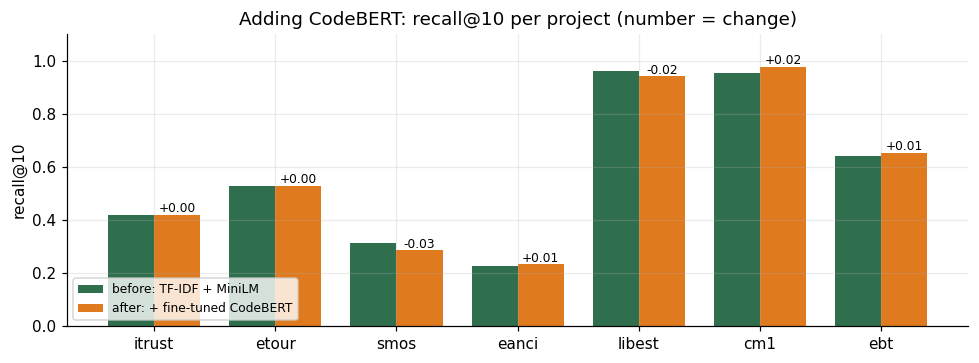

average recall@10: 0.578 -> 0.577


In [7]:
r = saved('stage1_codebert_real_projects.json')
ps = list(r['projects']); b = [r['projects'][p]['table']['TF-IDF + MiniLM (before)']['recall@10'] for p in ps]; a = [r['projects'][p]['table']['TF-IDF + MiniLM + CodeBERT (after)']['recall@10'] for p in ps]
x = np.arange(len(ps)); w = 0.38; fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(x - w / 2, b, w, color=color('TF-IDF + MiniLM'), label='before: TF-IDF + MiniLM'); ax.bar(x + w / 2, a, w, color=color('TF-IDF + MiniLM + CodeBERT'), label='after: + fine-tuned CodeBERT')
for i, (u, v) in enumerate(zip(b, a)): ax.text(i + w / 2, v + .01, f'{v - u:+.2f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(ps); ax.set_ylim(0, 1.1); ax.set_ylabel('recall@10'); ax.legend(fontsize=8, loc='lower left'); ax.set_title('Adding CodeBERT: recall@10 per project (number = change)'); plt.tight_layout(); plt.show()
m = r['mean_over_projects']; print('average recall@10:', round(m['TF-IDF + MiniLM (before)']['recall@10'], 3), '->', round(m['TF-IDF + MiniLM + CodeBERT (after)']['recall@10'], 3))

**Decision / honest reading.** The average does not change (0.578 → 0.577). CodeBERT is therefore kept only as an extra signal that does no harm, and it is **not** claimed as an improvement. The fine-tuning data was LLM-written, so a model trained on real labelled data (the cross-validation notebook) is the open next step.

## 5. Choice 3: a cross-encoder reranker after stage 1?

**Question.** A cross-encoder reads the requirement and the code *together* (slower, usually more accurate). Does re-ordering the stage-1 shortlist with one help?

**Compared:** stage 1 alone against stage 1 + reranker, for an untrained MiniLM cross-encoder, a fine-tuned MiniLM one, and a fine-tuned CodeBERT one, on 115 requirements of three projects never used for training. The table shows the **gain in the number of true links found in the top 5**, with its 95% bootstrap interval (an interval above 0 means the gain is real).

In [8]:
rr = saved('reranker.json')['heldout_retrieval_level']
print('data:', rr['datasets'])
for key, label in (('untrained_minilm_vs_stage1_all', 'untrained MiniLM cross-encoder'), ('finetuned_minilm_vs_stage1_all', 'fine-tuned MiniLM cross-encoder')):
    print(f'\n{label}'); [print(f'  {m:14s} {v}') for m, v in rr[key].items()]
print('\nfine-tuned CodeBERT cross-encoder:', rr['codebert_finetuned'])

data: LibEST, CM-1, EBT (115 requirements; never used in training)

untrained MiniLM cross-encoder
  hits@5_w0.5    +0.115 [+0.026,+0.209]
  hits@5_w1      +0.088 [-0.017,+0.200]
  MRR_w0.5       +0.015 [-0.021,+0.053]
  hits@3_w0.5    +0.009 [-0.070,+0.087]

fine-tuned MiniLM cross-encoder
  hits@5_w0.5    +0.157 [+0.070,+0.252]
  hits@5_w1      +0.138 [+0.017,+0.261]
  MRR_w0.5       +0.026 [-0.004,+0.058]
  hits@3_w0.5    +0.035 [-0.052,+0.122]

fine-tuned CodeBERT cross-encoder: worse than stage 1 alone (CM-1 MRR 0.211 vs 0.876); fused results inconsistent; not used


**Decision.** The MiniLM reranker gives a small gain in the top 5, but the order of the top 1 to 3 is not reliably better, and a fine-tuned model is no better than an untrained one. The CodeBERT cross-encoder was clearly **worse** than stage 1 alone. The reranker was therefore not made part of the pipeline.

**Limits:** the fusion weight was chosen after seeing test results; only 115 requirements; the numbers were computed in Colab and replayed here.

## 6. Choice 4: expand each query with the LLM?

**Question.** Letting the LLM write likely class and file names for each requirement, then searching with them: does stage-1 recall go up?

**Compared:** recall of the same 20 iTrust requirements with and without the expansion.

In [9]:
qe = saved('reranker.json')['query_expansion']
print('setup     :', qe['setup']); print('recall    :', qe['stage1_recall_hybrid']); print('conclusion:', qe['conclusion'])

setup     : Llama 3.1 8B asked once per requirement for likely class/method/file names; the words were appended to the requirement before stage-1 retrieval. 20 iTrust requirements with at least one true link (68 true links).
recall    : {'top5': {'plain': 0.338, 'expanded': 0.338}, 'top10': {'plain': 0.441, 'expanded': 0.441}, 'top20': {'plain': 0.544, 'expanded': 0.529}}
conclusion: no gain; the LLM guesses names that are not in the code


**Decision.** The expansion did not raise recall (top-10 0.441 before and after), because the LLM invents file names that do not exist in the code. It was not adopted.

## 7. Choice 5: which LLM verifies the links?

**Question.** Stage 2 asks an LLM "does this code implement this requirement?". Three locally hosted models were compared on the **same 60 requirement/code pairs** (30 true links, 30 non-links, from eTour and iTrust). Precision = of the links it accepted, how many were true; recall = of the true links, how many it accepted.

The numbers below are computed from the saved answers of each model (`llm_compare.json`).

                           precision    recall        F1
llama3.1-8k                    0.619     0.433     0.510
qwen2.5-coder-8k               0.818     0.300     0.439
gemma2-8k                      0.529     0.600     0.562
{'llama3.1-8k': 33, 'qwen2.5-coder-8k': 31, 'gemma2-8k': 50} (seconds per answer)
{'llama3.1-8k': 0, 'qwen2.5-coder-8k': 0, 'gemma2-8k': 4} (pairs where the model gave no usable answer, counted as "not linked")


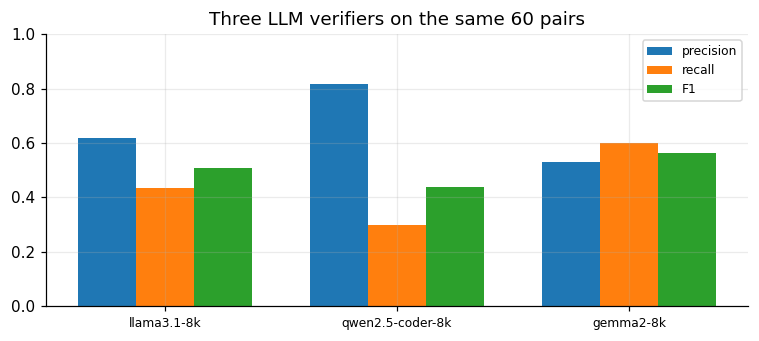

In [10]:
models = saved('llm_compare.json')['models']; rows_out = {}
for name, rows in models.items():
    no_answer = sum(r.get('linked') is None for r in rows)                 # the model gave no usable answer: counted as "not linked"
    linked = lambda r: bool(r.get('linked'))
    tp = sum(r['label'] == 1 and linked(r) for r in rows); fp = sum(r['label'] == 0 and linked(r) for r in rows); fn = sum(r['label'] == 1 and not linked(r) for r in rows)
    p, rc = tp / max(1, tp + fp), tp / max(1, tp + fn)
    rows_out[name.split(':')[0]] = {'precision': p, 'recall': rc, 'F1': 2 * p * rc / max(1e-9, p + rc), 'seconds per answer': float(np.mean([r['seconds'] for r in rows if r.get('seconds') is not None])), 'pairs': len(rows), 'no answer': no_answer}
show_table({k: {c: v[c] for c in ('precision', 'recall', 'F1')} for k, v in rows_out.items()}, ['precision', 'recall', 'F1'], width=26)
print({k: round(v['seconds per answer']) for k, v in rows_out.items()}, '(seconds per answer)')
print({k: v['no answer'] for k, v in rows_out.items()}, '(pairs where the model gave no usable answer, counted as "not linked")')
fig, ax = plt.subplots(figsize=(7, 3.2)); names_ = list(rows_out); xx = np.arange(len(names_))
for j, m_ in enumerate(('precision', 'recall', 'F1')): ax.bar(xx + (j - 1) * 0.25, [rows_out[n][m_] for n in names_], 0.25, label=m_)
ax.set_xticks(xx); ax.set_xticklabels(names_, fontsize=8); ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.set_title('Three LLM verifiers on the same 60 pairs'); plt.tight_layout(); plt.show()

**Decision / reading.** The three models trade precision against recall: one is strict (high precision, low recall), one lenient (high recall, low precision), and Llama 3.1 8B sits in between and is the one the pipeline was built and measured with. **Limit:** 60 pairs, so the differences are indicative, not statistically strong.

## 8. Choice 6: which prompt for the verifier?

**Question.** The default *expert* prompt accepts anything plausible. The *evidence* prompt makes the model quote code that satisfies the requirement, and the quote is checked against the code. Which gives better links?

**Compared** on 36 PetClinic links that were labelled correct / wrong by a reviewer (an AI reviewer, not a human; see the limits).

{'links_judged': 36, 'standard_precision': 0.583, 'evidence_kept': 17, 'evidence_precision': 0.824, 'correct_links_kept': '14/21', 'wrong_links_rejected': '12/15'}


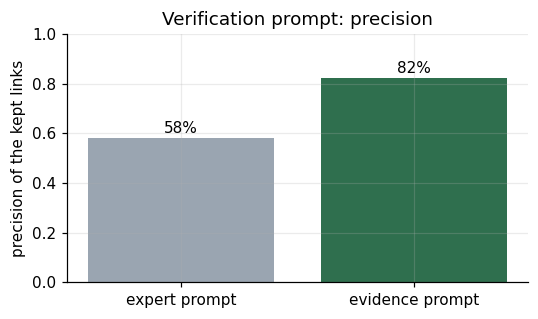

In [11]:
ev = saved('evidence_ab_spring-petclinic.json')['summary']
print({k: ev[k] for k in ('links_judged', 'standard_precision', 'evidence_kept', 'evidence_precision', 'correct_links_kept', 'wrong_links_rejected')})
fig, ax = plt.subplots(figsize=(5, 3)); ax.bar(['expert prompt', 'evidence prompt'], [ev['standard_precision'], ev['evidence_precision']], color=['#9aa5b1', '#2f6f4e'])
for i, v in enumerate([ev['standard_precision'], ev['evidence_precision']]): ax.text(i, v + .02, f'{v:.0%}', ha='center')
ax.set_ylim(0, 1); ax.set_ylabel('precision of the kept links'); ax.set_title('Verification prompt: precision'); plt.tight_layout(); plt.show()

**Decision / reading.** On PetClinic the evidence prompt raised precision from 58% to 82%, at the cost of rejecting about a third of the correct links (14 of 21 kept). **Limits, important:** one project, 36 links, labelled by an AI reviewer; and on a later project (the BMI calculator) the evidence prompt rejected correct links, so the dashboard uses the *expert* prompt. The prompt choice is therefore a precision/recall trade-off, not a free win.

## 9. Choice 7: how to detect that a link has decayed?

**Question.** When code or a requirement changes, how often is a broken link detected? Edits were injected into 11 verified links (46 breaking edits plus 22 harmless ones as controls).

**Compared:** the LLM alone against the LLM plus a *meaning-change check* (compares numbers, negations, true/false and operators with the text when the link was verified).

LLM + meaning-change check: detected 95.7% of breaking edits (95% interval 86% to 99%); false alarms on harmless edits 0%
LLM alone (earlier measurement, docs 5.z): 76.1% (62% to 86%)


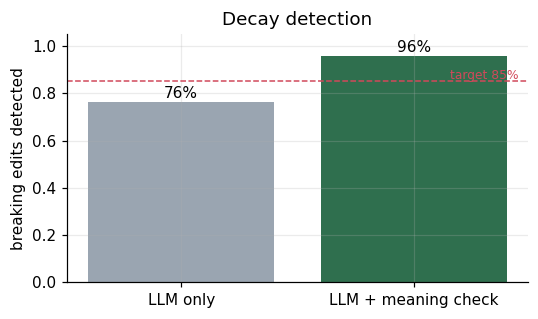

In [12]:
dv3 = saved('decay_injection_v3.json'); lo, hi = dv3['decay_detection_ci95']
print(f"LLM + meaning-change check: detected {dv3['decay_detection_accuracy']:.1%} of breaking edits (95% interval {lo:.0%} to {hi:.0%}); false alarms on harmless edits {dv3['false_decay_rate']:.0%}")
print('LLM alone (earlier measurement, docs 5.z): 76.1% (62% to 86%)')
fig, ax = plt.subplots(figsize=(5, 3)); ax.bar(['LLM only', 'LLM + meaning check'], [0.761, dv3['decay_detection_accuracy']], color=['#9aa5b1', '#2f6f4e'])
for i, v in enumerate([0.761, dv3['decay_detection_accuracy']]): ax.text(i, v + .02, f'{v:.0%}', ha='center')
ax.axhline(0.85, color='#d1495b', ls='--', lw=1); ax.text(1.45, 0.86, 'target 85%', color='#d1495b', fontsize=8, ha='right')
ax.set_ylim(0, 1.05); ax.set_ylabel('breaking edits detected'); ax.set_title('Decay detection'); plt.tight_layout(); plt.show()

**Decision / reading.** The check lifts detection from 76% to 96% because a changed number or a negation is exactly what a small LLM misses. **Limits:** the check was designed around these kinds of edits, so the number is favourable; real edits are more varied; the sample is small (11 usable links).

## 10. What was NOT reached (say it before you are asked)

| Target | Measured | Met? |
|---|---|---|
| Precision ≥ 90% | 37.5% on the iTrust sample (full pipeline) | No |
| Recall ≥ 80% | stage 1: 41.6% at top-10 on iTrust | No |
| Verification latency ≤ 5 s | about 52 s per answer on a CPU-only server | No |
| Decay detection ≥ 85% | 95.7% (with the meaning check) | Yes |

Being open about the targets that were not met is part of the evidence: every number in this notebook is a measured one.

## What to say about this notebook

* For each choice, the alternatives were compared on the same data with the same metric; the notebook shows the numbers.
* The stage-1 embedding comparison is **re-run live** here and reproduces the saved results; the others are read from result files measured earlier (GPU or the slow LLM server).
* Every comparison states its limits; none is presented as proof beyond what its sample supports.